In [41]:
import pandas as pd
import numpy as np
import os
from glob import glob
from sklearn.metrics import roc_curve, auc, balanced_accuracy_score, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
import scipy
from scipy.optimize import brentq
from scipy.interpolate import interp1d

import seaborn as sns
import random
import torch
import torchaudio
import librosa
import matplotlib.pyplot as plt
from IPython.display import Audio, display

import pysptk
import scipy.signal as sps
import scipy.ndimage as ndi

In [233]:
def compute_cllr(scores, labels):
    scores = np.array(scores)
    labels = np.array(labels)
    tar = scores[labels == 1]
    non = scores[labels == 0]
    c1 = np.mean(np.log2(1 + np.exp(-tar)))
    c2 = np.mean(np.log2(1 + np.exp(non)))
    return (c1 + c2) / 2

def print_metrics(scores, labels):
    fpr, tpr, thres = roc_curve(labels, scores)
    rocauc = auc(fpr, tpr)
    fnr = 1 - tpr
    eer_func = interp1d(fpr, fnr)
    eer = brentq(lambda x: eer_func(x) - x, 0., 1.)
    cllr = compute_cllr(scores, labels)
    
    preds = (scores >= 0).astype(int)
    
    bacc = balanced_accuracy_score(preds, labels)
    acc = accuracy_score(preds, labels)
    prec = precision_score(labels, preds)
    rec = recall_score(labels, preds)
    f1 = f1_score(labels, preds)

    header = f"{'AUC%':>8} {'EER%':>8} {'Cllr':>8} {'B.Acc.':>8} {'Acc.':>8} {'Prec.':>8} {'Recall':>8} {'F1':>8}"
    print(header)
    print(f"{rocauc*100:>8.2f} "
          f"{eer*100:>8.2f} "
          f"{cllr:>8.4f} "
          f"{bacc*100:>8.2f} "
          f"{acc*100:>8.2f} "
          f"{prec*100:>8.2f} "
          f"{rec*100:>8.2f} "
          f"{f1*100:>8.2f}")

def load_results(path):
    logLR_scores = np.load(os.path.join(path, "scores_per_expert.npy"))
    logit_scores = np.load(os.path.join(path, "raw_logits_per_expert.npy"))
    labels = np.load(os.path.join(path, "labels.npy"))
    attack_ids = np.load(os.path.join(path, "attack_ids.npy"))
    return logit_scores, logLR_scores, labels, attack_ids
    
def plot_distributions(real_scores, fake_scores, lbound=None, hbound=None, thr=0, ax=None, metrics=True):

    labels = np.concatenate([
        np.zeros(len(real_scores)),
        np.ones(len(fake_scores))
    ])
    
    if metrics:
        print_metrics(np.concatenate([real_scores, fake_scores]), labels)
        print()
        print(f"   Real mean score: {real_scores.mean():.4f}")
        print(f"   Fake mean score: {fake_scores.mean():.4f}\n")
        
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))

    sns.kdeplot(real_scores, fill=True, alpha=0.5, label="Real (0)", ax=ax)
    sns.kdeplot(fake_scores, fill=True, alpha=0.5, label="Fake (1)", ax=ax)

    ax.axvline(thr, linestyle="--", linewidth=2, color="red")
    
    if lbound is not None:
        ax.axvspan(lbound, hbound, color="yellow", alpha=0.3)
        
    ax.legend() 
    
def show_per_attack_per_expert(scores, labels, attack_ids, selected_attack=None, show_metrics=False):
    print("\n#--------- PER ATTACK, PER EXPERT ---------#\n")
    # SEPARATE SCORES FOR REAL AND SCORES FOR FAKES, FOR EVERY EXPERT

    n_exp = scores.shape[0]

    attack_ids = attack_ids.squeeze()
    labels = labels.squeeze()
    real_mask = (labels == 0)
    fake_mask = ~real_mask

    real_scores = {
        exp: scores[exp, real_mask]
        for exp in range(n_exp)
    }

    if selected_attack:
        unique_attacks = np.array(selected_attack)
    else:
        unique_attacks = np.unique(attack_ids)
        
    unique_attacks = unique_attacks[unique_attacks != '-']  # remove real
    attack_scores = {
        a: {
            exp: scores[exp, (attack_ids == a) & fake_mask]
            for exp in range(n_exp)
        }
        for a in unique_attacks
    } 

    # PLOT DISTRIBUTIONS ON EVERY ATTACK, FOR EACH EXPERT (ALL REAL SAMPLES vs FAKE SCORES ON THE GIVEN ATTACK)
  
    n_att = len(unique_attacks)
    n_exp = scores.shape[0]
    
    fig, axes = plt.subplots(n_att, n_exp, figsize=(5*n_exp, 3*n_att))
    
    thr = 0
    lbound = np.percentile(scores, 5)
    hbound = np.percentile(scores, 95)
    
    for i, a in enumerate(unique_attacks):
        for exp in range(n_exp):
            ax = axes[i, exp] if n_att > 1 else axes[exp]
    
            real_exp_scores = real_scores[exp]
            fake_exp_scores = attack_scores[a][exp]
    
            plot_distributions(
                real_exp_scores,
                fake_exp_scores,
                lbound,
                hbound,
                thr=thr,
                ax=ax,
                metrics=show_metrics
            )
    
            if i == 0:
                ax.set_title(f"Exp {exp}")
            if exp == 0:
                ax.set_ylabel(f"{a}")
    
    plt.tight_layout()
    plt.show()

def analyze_experts_distributions(rootpath, selected_TTS, show_logits=False, show_metrics=False):
    selected_attacks = [selected_TTS]
    logits, llr_scores, labels, attack_ids = load_results(rootpath)
    
    if show_logits:
        print("\n######################### LOGITS #########################")
        show_per_attack_per_expert(logits, labels, attack_ids, selected_attacks, show_metrics=show_metrics)
        
    print("\n######################### LLR #########################")
    show_per_attack_per_expert(llr_scores, labels, attack_ids, selected_attacks, show_metrics=show_metrics)
    
def show_ensemble(scores, labels): 
    print("\n#--------- OVERALL ENSEMBLE (sum LogLR) ---------#\n")
    sum_logLR_scores = np.sum(scores, axis=0)
    real_ens_scores = sum_logLR_scores[labels == 0]
    fake_ens_scores = sum_logLR_scores[labels == 1]

    plot_distributions(real_ens_scores, fake_ens_scores, metrics=True)
    plt.show()  

def select_samples_by_score(
    scores,
    labels,
    attack_ids,
    rootpath,
    expert_id,
    attack=None,
    min_score=-np.inf,
    max_score=np.inf,
    pick_fakes=True,
    limit=None,
):
    filenames = np.load(f"{rootpath}/filenames.npy")
    attack_ids = attack_ids.squeeze()
    labels = labels.squeeze()

    # expert scores
    exp_scores = scores[expert_id]

    if pick_fakes:
        # fake samples only 
        mask = labels != 0
        # mask for selected attack
        attack_mask = (attack_ids == attack)
    else:
        mask = labels == 0

    # score range mask
    score_mask = (exp_scores >= min_score) & (exp_scores <= max_score)

    if pick_fakes:
        final_mask = mask & attack_mask & score_mask
    else:
        final_mask = mask & score_mask

    indices = np.where(final_mask)[0]

    if limit is not None:
        indices = random.sample(list(indices), min(limit, len(indices)))

    selected_files = filenames[indices]
    return indices, selected_files, exp_scores[indices]

def extract_samples_to_investigate(rootpath, selected_expert, min_score, max_score, root_audio, limit=5, investigate_fake_samples=True): 
    logits, llr_scores, labels, attack_ids = load_results(rootpath)
    
    indices, files, selected_scores = select_samples_by_score(llr_scores, labels, attack_ids, rootpath,
                                                                expert_id=selected_expert, attack=selected_TTS,
                                                                min_score=min_score, max_score=max_score,
                                                                pick_fakes=investigate_fake_samples, limit=limit)
    
    full_paths = np.array([os.path.join(root_audio, f + '.flac') for f in files])
    #full_paths = np.array([os.path.join(root_audio, f + '.wav') for f in files])
    
    for idx, (p, s) in enumerate(zip(full_paths, selected_scores)):
        print(idx, s, p)

    if investigate_fake_samples:
        idx, (best_path, max_score) = max(enumerate(zip(full_paths, selected_scores)),key=lambda x: x[1][1])
    else:
        idx, (best_path, min_score) = min(enumerate(zip(full_paths, selected_scores)),key=lambda x: x[1][1])

    return idx, full_paths
    
def show_audio_and_spectrogram(
    path,
    sr=16000,
    trim=False,
    normalize=False,
    windowing=False
):
    waveform, sample_rate = librosa.load(path, sr=None, mono=True)
    waveform = torch.tensor(waveform).float()

    if sample_rate != sr:
        resampler = torchaudio.transforms.Resample(orig_freq=sample_rate, new_freq=sr)
        waveform = resampler(waveform.unsqueeze(0)).squeeze(0)
    if normalize:
        peak = waveform.abs().max()
        if peak > 0:
            waveform = waveform / peak
    if trim:
        top_db = 40
        thr = 10 ** (-top_db / 20)
        idx = (waveform.abs() > thr).nonzero(as_tuple=True)[0]
        if idx.numel() > 0:
            waveform = waveform[idx[0]:idx[-1] + 1]

    spec = torchaudio.transforms.Spectrogram(n_fft=512, hop_length=256, power=2)(waveform.unsqueeze(0)).squeeze(0)
    spec_db = torchaudio.functional.amplitude_to_DB(spec, multiplier=10.0, amin=1e-10, db_multiplier=0)

    # --- plot and display---
    display(Audio(waveform.numpy(), rate=sr))
    plt.figure(figsize=(10, 4))
    plt.imshow(spec_db.numpy(), aspect="auto", origin="lower")
    plt.title(path.split("/")[-1])
    plt.colorbar()
    plt.tight_layout()
    plt.show()

    return waveform

def lsf_extraction(waveform, order=20, frame_length=256, hop_length=256):
    waveform = waveform + 1e-6 * np.random.randn(len(waveform))
    waveform = waveform.astype(np.float64)
    frames = [waveform[i:i + frame_length] for i in range(0, len(waveform) - frame_length, hop_length)]
    frames = np.stack(frames)
    window = scipy.signal.get_window('blackman', frame_length, fftbins=False)
    windowed_frames = frames * window
    lpc_coeffs = pysptk.lpc(windowed_frames, order)
    try:
        lsf = pysptk.lpc2lsp(lpc_coeffs)
        return lsf
    except RuntimeError:
        gamma = 0.9
        lpc_stable = lpc_coeffs * (gamma ** np.arange(lpc_coeffs.shape[1]))
        return pysptk.lpc2lsp(lpc_stable)
    return lsf

def plot_lsf(path):
    waveform, _ = librosa.load(path, sr=16000, mono=True)
    lsf = lsf_extraction(waveform)
    
    fig = plt.figure(figsize=(10, 4))
    plt.plot(lsf, alpha=0.8)
    plt.grid(True, alpha=0.3)
    plt.show()

def plot_upsampling_feature(
    x,
    sr=16000,
    n_fft=512,
    hop_length=256,
    baseline_win=32,
    fmin=1000,
    fmax=8000,
):
    x = np.asarray(x, dtype=np.float32)
    f, t, Z = sps.stft(
        x, fs=sr,
        nperseg=n_fft, noverlap=n_fft - hop_length,
        boundary=None, padded=False,)

    S = np.abs(Z)
    S_mean = np.mean(S, axis=1)  # average spectrum
    mask = (f >= fmin) & (f <= fmax)
    S_mean = S_mean[mask] # band-limit
    baseline = ndi.minimum_filter1d(S_mean, size=baseline_win) # baseline removal
    fingerprint = S_mean - baseline
    fingerprint = np.maximum(fingerprint, 0.0) # keep only peaks
    fingerprint /= (np.linalg.norm(fingerprint) + 1e-8) # normalization (L2)
    fingerprint.astype(np.float32)

    plt.figure(figsize=(8, 3))
    plt.plot(fingerprint)
    plt.ylim([0, 0.8])
    plt.tight_layout()
    plt.show()

# ASVspoof 2019


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

    AUC%     EER%     Cllr   B.Acc.     Acc.    Prec.   Recall       F1
   86.94    21.59   0.6823    60.42    65.21    98.46    62.04    76.12

   Real mean score: -1.1851
   Fake mean score: 0.7037



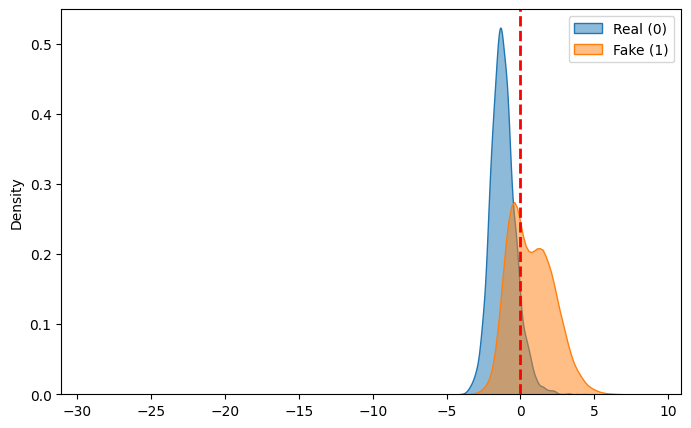

In [71]:
rootpath = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_mix/CMLG/5_experts/Cset_ASV19_pooled_30"
logits, llr_scores, labels, attack_ids = load_results(rootpath)
show_ensemble(llr_scores, labels)

### Choose the TTS and plot experts distributions


######################### LLR #########################

#--------- PER ATTACK, PER EXPERT ---------#



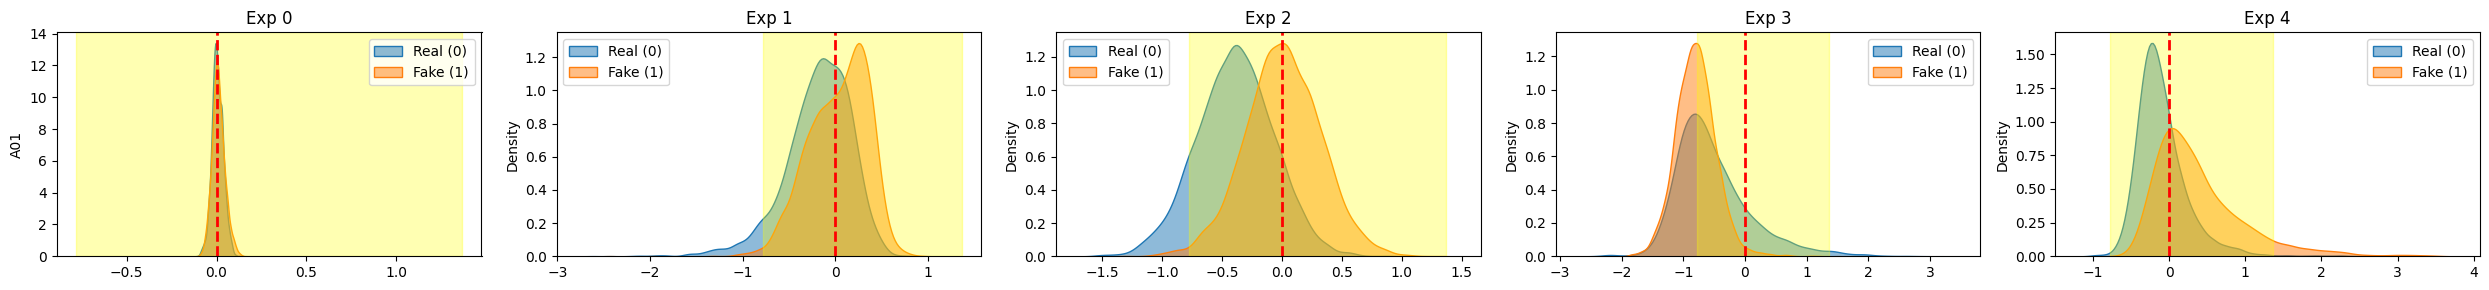

In [72]:
selected_TTS = 'A01'
analyze_experts_distributions(rootpath, selected_TTS, show_logits=False)

### Select one expert 

In [73]:
selected_expert = 4               # draw samples to investigate from this expert's score distribution 

### Plot a real sample

0 -0.8298521624983859 /Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_eval/flac/LA_E_4705575.flac
1 -0.8116844024075787 /Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_eval/flac/LA_E_2175003.flac
2 -0.8161784467829494 /Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_eval/flac/LA_E_7892728.flac
3 -0.8455155841964925 /Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_eval/flac/LA_E_2736649.flac
4 -0.8614447494862414 /Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_eval/flac/LA_E_5322895.flac


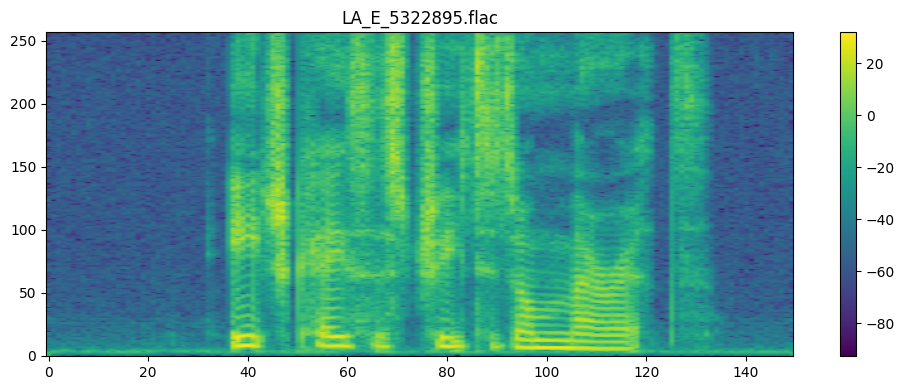

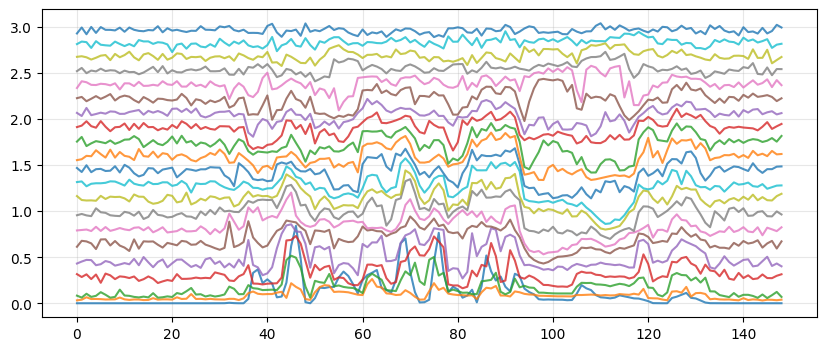

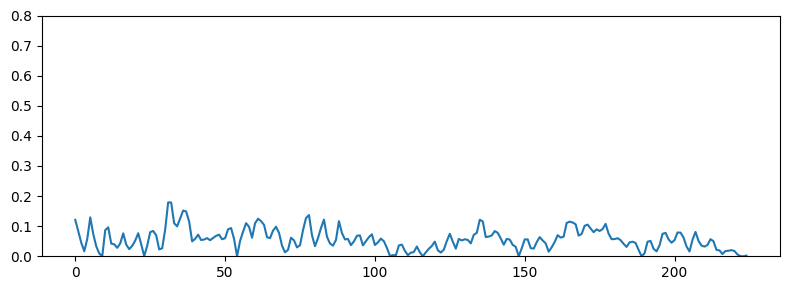

In [90]:
min_score = -1                      # lower score bound for extracting samples
max_score = -0.8                    # upper score bound for extracting samples

root_audio = "/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_eval/flac"
idx, full_paths = extract_samples_to_investigate(rootpath, selected_expert, min_score, max_score, root_audio, investigate_fake_samples=False)

path = full_paths[idx]
wav = show_audio_and_spectrogram(path)
plot_lsf(path)
plot_upsampling_feature(wav)

### Plot a fake sample

0 2.356357880546554 /Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_dev/flac/LA_D_6029194.flac
1 2.0778676910596774 /Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_dev/flac/LA_T_9847615.flac
2 2.3032279131532474 /Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_dev/flac/LA_D_5624531.flac
3 2.384192976750251 /Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_dev/flac/LA_D_6653512.flac
4 2.378441847202997 /Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_dev/flac/LA_T_7096119.flac


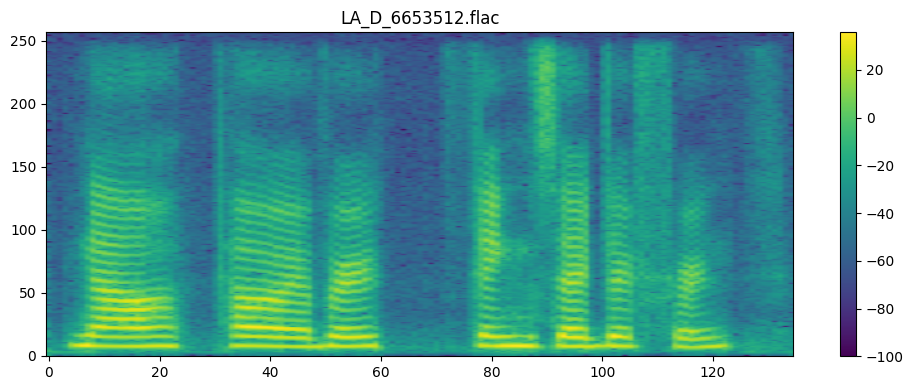

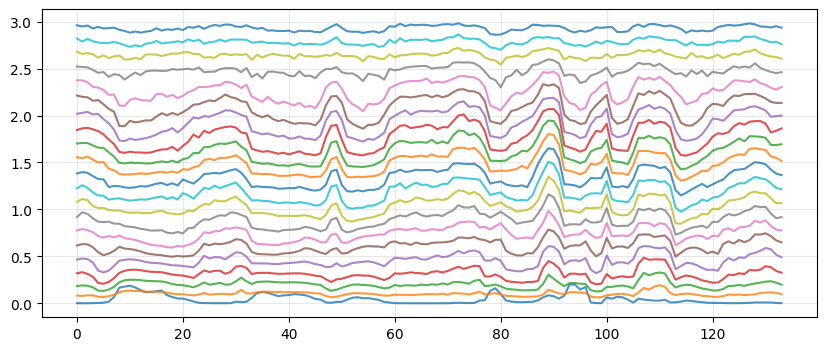

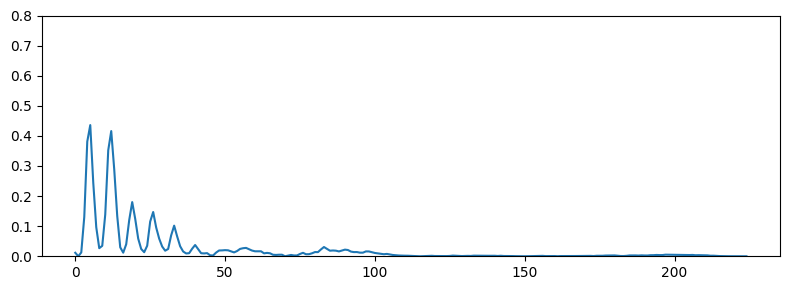

In [83]:
min_score = 2                     # lower score bound for extracting samples
max_score = 3                     # upper score bound for extracting samples

root_audio = "/Database/ASVspoof2019/public_released_data/LA/ASVspoof2019_LA_dev/flac"
idx, full_paths = extract_samples_to_investigate(rootpath, selected_expert, min_score, max_score, root_audio, investigate_fake_samples=True)

path = full_paths[idx]
wav = show_audio_and_spectrogram(path)
plot_lsf(path)
plot_upsampling_feature(wav)

## ASVspoof 5


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

    AUC%     EER%     Cllr   B.Acc.     Acc.    Prec.   Recall       F1
   64.16    39.40   1.0042    56.65    46.65    88.67    38.14    53.33

   Real mean score: -0.6230
   Fake mean score: -0.0588



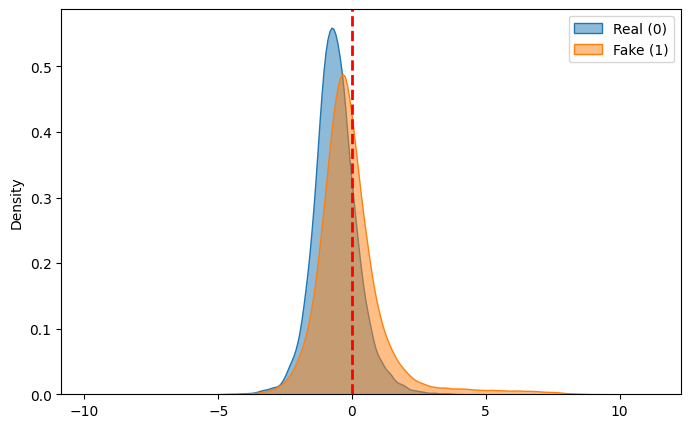

In [228]:
rootpath = f"/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv5/experts_trained_on_mix/CMLG/5_experts/Cset_ASV19_pooled_30"
logits, llr_scores, labels, attack_ids = load_results(rootpath)
show_ensemble(llr_scores, labels)

### Choose the TTS and plot experts distributions


######################### LLR #########################

#--------- PER ATTACK, PER EXPERT ---------#



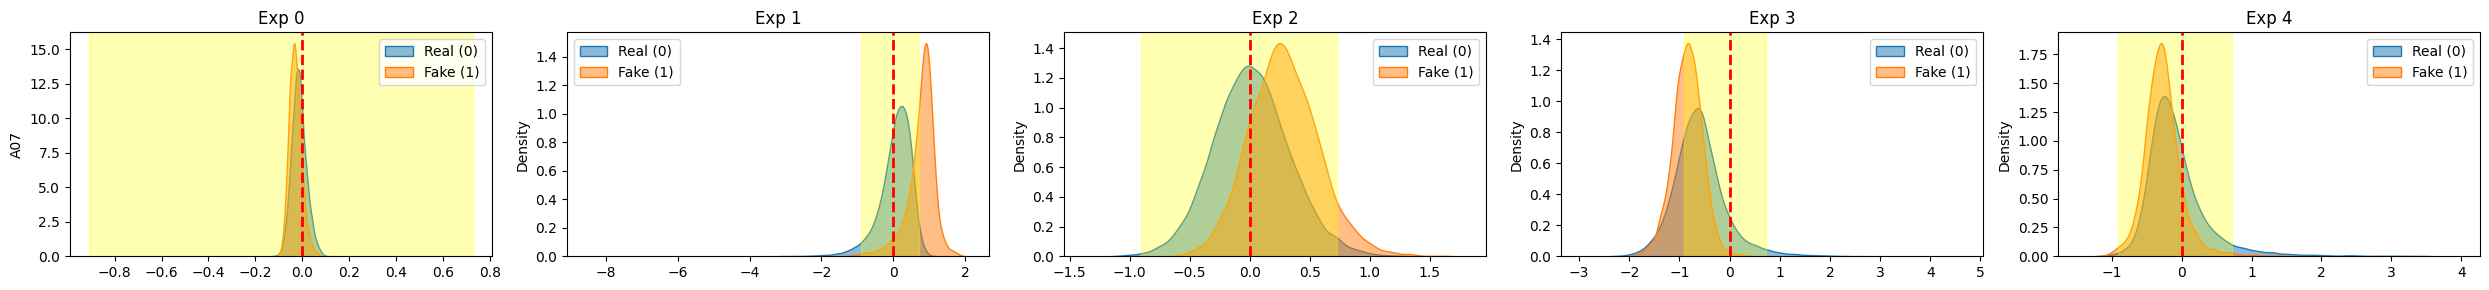

In [229]:
selected_TTS = 'A07'
analyze_experts_distributions(rootpath, selected_TTS, show_logits=False)

### Select one expert

In [230]:
selected_expert = 1                # draw samples to investigate from this expert's score distribution 

### Plot a real sample

0 -1.1974841399928395 /Database/ASVspoof5/flac_E_eval/E_0009166030.flac
1 -1.3794512873342712 /Database/ASVspoof5/flac_E_eval/E_0009719712.flac
2 -1.9218148163434285 /Database/ASVspoof5/flac_E_eval/E_0003268214.flac
3 -1.3957767712990117 /Database/ASVspoof5/flac_E_eval/E_0007195069.flac
4 -1.5413598659038998 /Database/ASVspoof5/flac_E_eval/E_0001823028.flac


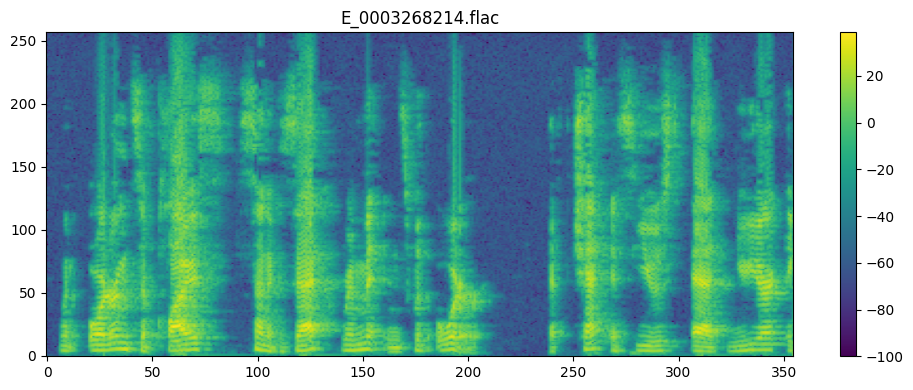

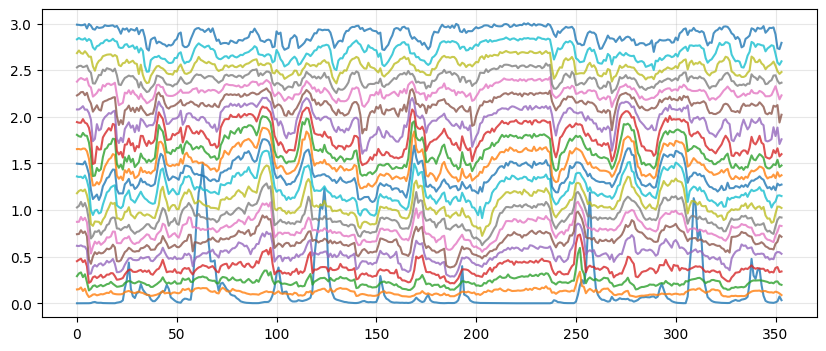

In [234]:
min_score = -2                     # lower score bound for extracting samples
max_score = -1                     # upper score bound for extracting samples2 pm edt to japan time

root_audio = "/Database/ASVspoof5/flac_E_eval"
idx, full_paths = extract_samples_to_investigate(rootpath, selected_expert, min_score, max_score, root_audio, investigate_fake_samples=False)

path = full_paths[idx]
show_audio_and_spectrogram(path)
plot_lsf(path)

### Plot a fake sample

0 1.0029895623646832 /Database/ASVspoof5/flac_T/T_0000132998.flac
1 1.1915330179314347 /Database/ASVspoof5/flac_T/T_0000117559.flac
2 1.1111555991848716 /Database/ASVspoof5/flac_T/T_0000148434.flac
3 1.0563770558638406 /Database/ASVspoof5/flac_T/T_0000178957.flac
4 1.2045037745792182 /Database/ASVspoof5/flac_T/T_0000009109.flac


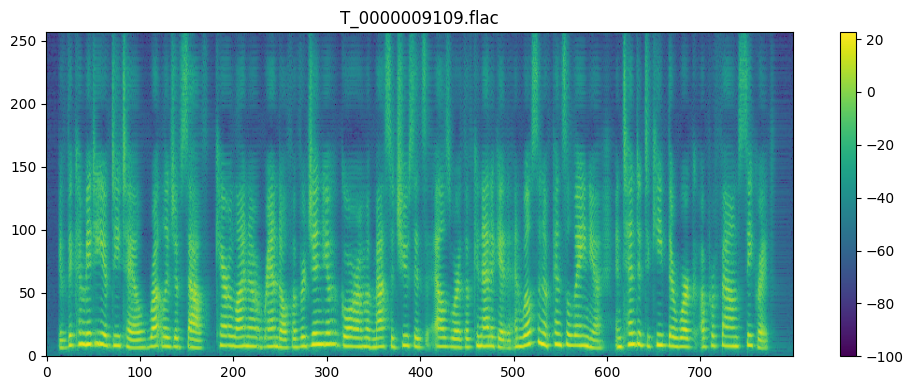

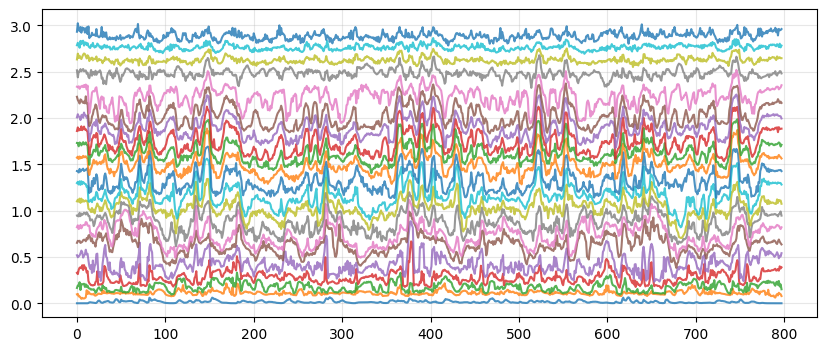

In [236]:
min_score = 1                     # lower score bound for extracting samples
max_score = 2                     # upper score bound for extracting samples

root_audio = "/Database/ASVspoof5/flac_T"
idx, full_paths = extract_samples_to_investigate(rootpath, selected_expert, min_score, max_score, root_audio, investigate_fake_samples=True)

path = full_paths[idx]
show_audio_and_spectrogram(path)
plot_lsf(path)

## SpoofCeleb


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

    AUC%     EER%     Cllr   B.Acc.     Acc.    Prec.   Recall       F1
   65.61    38.56   1.0771    52.50    31.04    98.24    27.58    43.07

   Real mean score: -1.0502
   Fake mean score: -0.4748



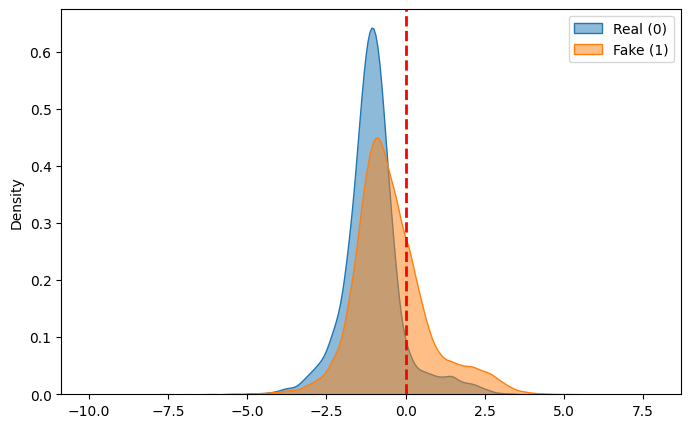

In [93]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/sc/experts_trained_on_mix/CMLG/5_experts/Cset_ASV19_pooled_30"
logits, llr_scores, labels, attack_ids = load_results(rootpath)
show_ensemble(llr_scores, labels)

## Mlaad 


#--------- OVERALL ENSEMBLE (sum LogLR) ---------#

    AUC%     EER%     Cllr   B.Acc.     Acc.    Prec.   Recall       F1
   83.23    24.97   0.7661    61.86    57.79    97.00    51.19    67.01

   Real mean score: -1.1851
   Fake mean score: 0.6288



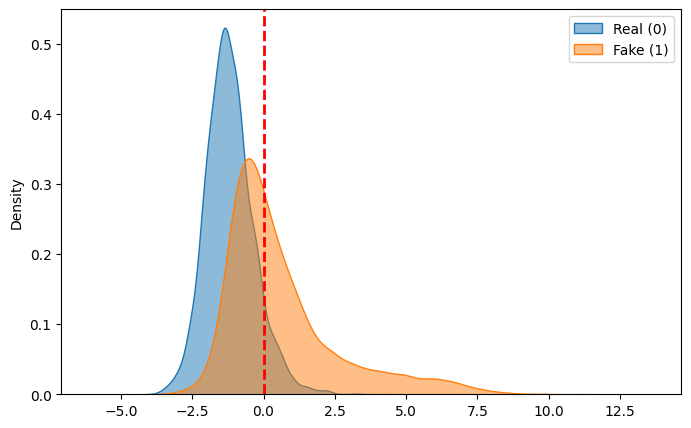

In [151]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/mlaad/experts_trained_on_mix/CMLG/5_experts/Cset_ASV19_pooled_30_REAL_from_ASV19_eval"
logits, llr_scores, labels, attack_ids = load_results(rootpath)
show_ensemble(llr_scores, labels)


######################### LOGITS #########################

#--------- PER ATTACK, PER EXPERT ---------#



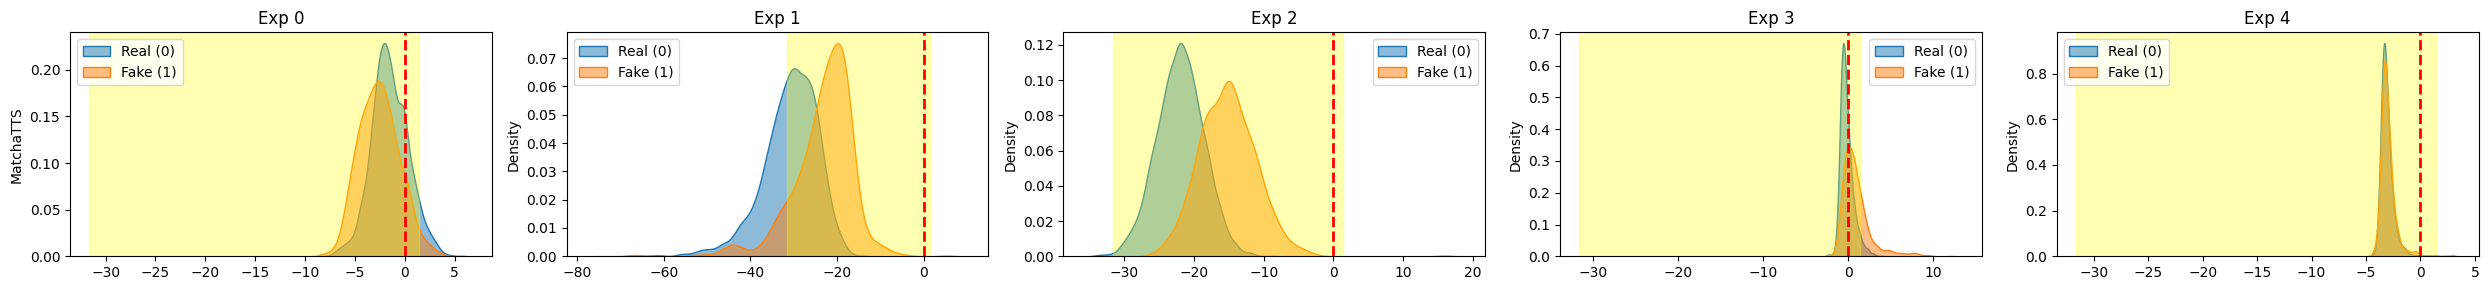


######################### LLR #########################

#--------- PER ATTACK, PER EXPERT ---------#



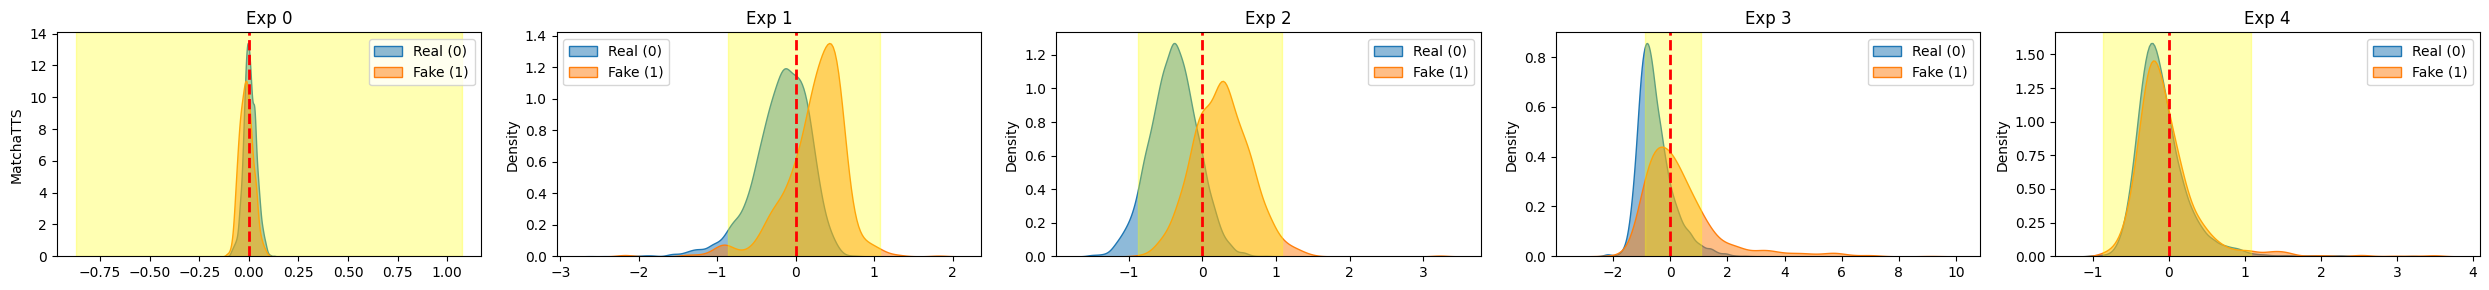

In [152]:
selected_TTS = 'MatchaTTS'
analyze_experts_distributions(rootpath, selected_TTS, show_logits=True)

In [ ]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/mlaad/experts_trained_on_mix/CMLG/5_experts/Cset_ASV19_pooled_30"
logits, llr_scores, labels, attack_ids = load_results(rootpath)
show_ensemble(llr_scores, labels)

In [ ]:
selected_TTS = 'MatchaTTS'
analyze_experts_distributions(rootpath, selected_TTS, show_logits=True)

In [150]:
selected_expert = 3                # draw samples to investigate from this expert's score distribution 

0 -0.5783399667509759 /Database/MLAAD/v5/fake/en/MatchaTTS/piratesofersatz_10_leinster_64kb_f000144.wav
1 -0.549519518114464 /Database/MLAAD/v5/fake/en/MatchaTTS/northandsouth_07_f000091.wav
2 -0.5861648878218113 /Database/MLAAD/v5/fake/en/MatchaTTS/jane_eyre_10_f000125.wav
3 -0.3079790122811504 /Database/MLAAD/v5/fake/en/MatchaTTS/pink_fairy_book_38_f000148.wav
4 -0.34769566911518274 /Database/MLAAD/v5/fake/en/MatchaTTS/the_master_key_10_f000089.wav


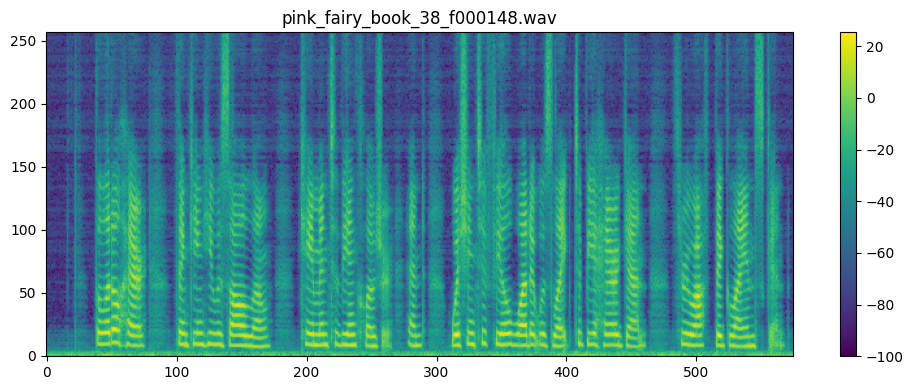

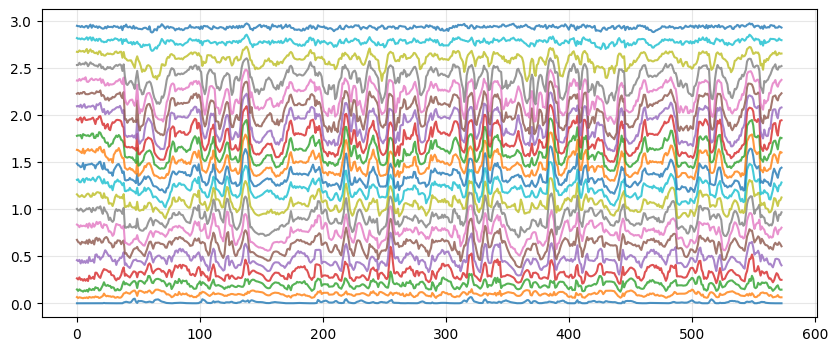

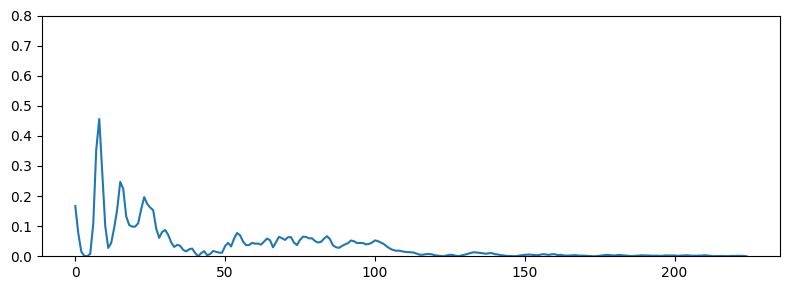

In [136]:
min_score = -0.75                     # lower score bound for extracting samples
max_score = -0.25                     # upper score bound for extracting samples

root_audio = f"/Database/MLAAD/v5/fake/en/{selected_TTS}"
idx, full_paths = extract_samples_to_investigate(rootpath, selected_expert, min_score, max_score, root_audio, limit=5, investigate_fake_samples=True)

path = full_paths[idx]
wav = show_audio_and_spectrogram(path)
plot_lsf(path)
plot_upsampling_feature(wav)